# NumPy Array Arithmetic

## Setup

Helpers and data: the midterm from Session 14, a house in the plane, and the face and chessboard images.

In [83]:
import numpy as np

students = ["Ana", "Bruno", "Chloe", "Diego", "Emma", "Farid"]
weights = np.array([20, 20, 10, 10, 10, 5, 5, 5, 5, 5, 5])
marks = np.array([
    [0.75, 1, 0.5, 1, 0.5, 1, 1, 0, 1, 1, 1],
    [0.5, 0.25, 1, 0.5, 0, 1, 0, 1, 1, 0, 1],
    [1, 1, 1, 1, 0.5, 1, 1, 1, 0, 1, 1],
    [0.25, 0.5, 0.5, 0.5, 0.5, 0, 1, 0, 1, 0, 1],
    [1, 1, 0.5, 1, 1, 1, 0, 1, 1, 1, 1],
    [0.5, 0.5, 0.5, 0, 1, 1, 1, 0, 0, 1, 0],
])

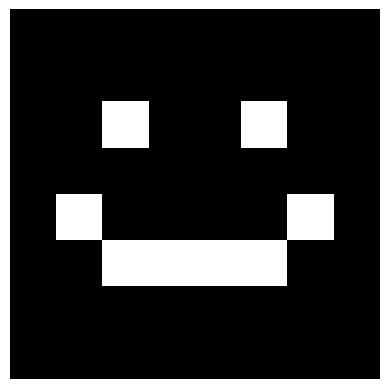

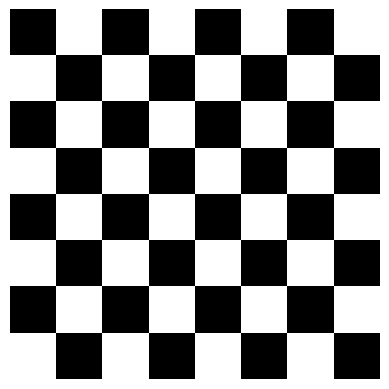

In [84]:
import matplotlib.pyplot as plt


def show(image):
    """Display a 2D array as a grayscale image (0 = black, 1 = white)."""
    plt.imshow(image, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.show()

face = np.zeros((8, 8))
face[2, 2] = 1
face[2, 5] = 1
face[5, 2:6] = 1
face[4, 1] = 1
face[4, 6] = 1

show(face)

board = np.zeros((8, 8))
board[::2, 1::2] = 1
board[1::2, ::2] = 1

show(board)

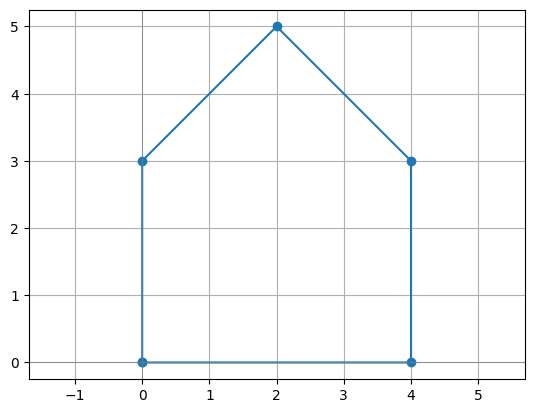

In [85]:
def draw(*shapes):
    """Draw one or more polygons given as arrays of points with shape (n, 2)."""
    for shape in shapes:
        closed = np.vstack([shape, shape[:1]])
        plt.plot(closed[:, 0], closed[:, 1], marker="o")
    plt.axhline(0, color="gray", linewidth=0.5)
    plt.axvline(0, color="gray", linewidth=0.5)
    plt.axis("equal")
    plt.grid(True)
    plt.show()


house = np.array([[0, 0], [4, 0], [4, 3], [2, 5], [0, 3]])
corners = ["bottom-left", "bottom-right", "top-right", "roof", "top-left"]

draw(house)

## Today's goal: the final grades in one line

Closing Session 14. This is how we compute the final grade of every student:

```python
np.sum(marks * weights, axis=1) / 10
```

**We are going to learn this today.** By the end of the class you will understand every piece: `*`, why `marks` and `weights` can be multiplied, and `axis`.

In [67]:
np.sum(marks * weights, axis=1) / 10

array([8. , 5. , 9. , 4.5, 9. , 5. ])

### With what we knew: loops

The points of a student in one exercise are her mark times the value of the exercise. The final score is the sum over all exercises; divided by 10, the grade.

**Live coding:** the nested-loop version. Compare its length with the line above.

In [68]:
final_grades = []
for row in marks:
    total = 0
    for j in range(len(weights)):
        total = total + row[j] * weights[j]
    final_grades.append(float(total / 10))
print(final_grades)

[8.0, 5.0, 9.0, 4.5, 9.0, 5.0]


## Element-wise operations

Same shape → the operator acts element by element.

- One student: `marks[0] * weights`
- Vectors, as in linear algebra: `u + v`, `3 * u`
- Warning: `u * v` is **not** the dot product.

Also `-`, `/`, `**`: see the notes.

In [69]:
ana = marks[0]
print(ana * weights)

u = np.array([1, 2, 3])
v = np.array([4, 0, -1])
print(u + v, 3 * u, u * v)

[15. 20.  5. 10.  5.  5.  5.  0.  5.  5.  5.]
[5 2 2] [3 6 9] [ 4  0 -3]


### Exercise: A linear combination

With `w = np.array([0, 1, 1])`, compute $2u - v + 3w$ without a loop.

In [70]:
w = np.array([0, 1, 1])
print(2 * u - v + 3 * w)

[-2  7 10]


### Images are arrays too

Try live: `show(1 - face)` (negative), then blend two images as a linear combination:

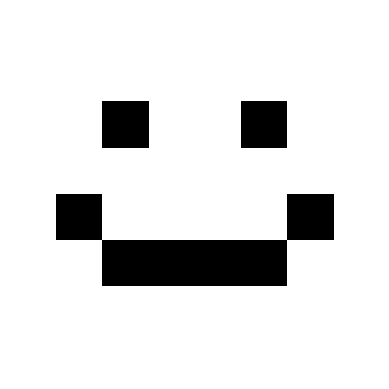

In [86]:
show(1 - face)

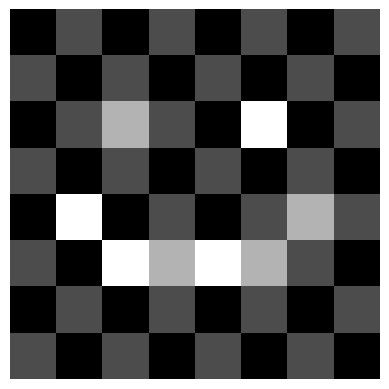

In [87]:
show(0.7 * face + 0.3 * board)

## Broadcasting

`marks` is `(6, 11)`, `weights` is `(11,)`, and `marks * weights` works. Why?

- Compare shapes from the **right**.
- Compatible if equal, or one of them is 1.
- The smaller array is stretched.

```text
marks     (6, 11)
weights       (11,)  -> (1, 11) -> (6, 11)
```

**Live coding with the house** `(5, 2)`:

1. `2 * house + np.array([3, 1])`: scale and move. Draw it.
2. Pull the roof: `pull = np.array([1, 1, 1, 1.5, 1])`. Why does `house * pull` fail? Fix it with `pull.reshape(5, 1)`.

(6, 11)


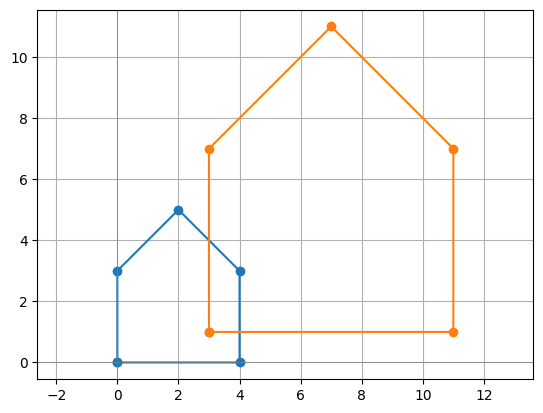

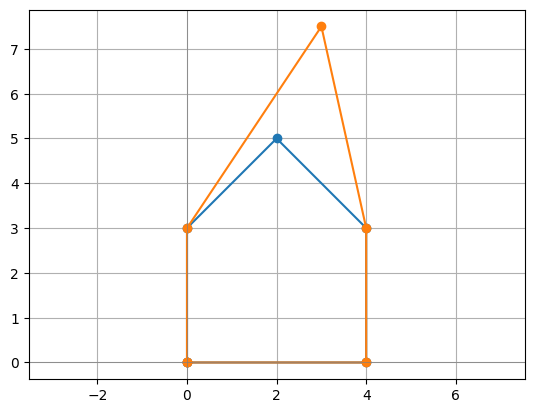

In [72]:
points = marks * weights
print(points.shape)

moved = 2 * house + np.array([3, 1])
draw(house, moved)

pull = np.array([1, 1, 1, 1.5, 1])
# house * pull                       # ValueError: (5, 2) and (5,)
draw(house, house * pull.reshape(5, 1))

### Exercise: Which shapes broadcast?

Without running code: which can be added to `house`, shape `(5, 2)`?

1. `0.5`  2. `(2,)`  3. `(5,)`  4. `(1, 2)`  5. `(5, 1)`  6. `(3, 2)`

In [73]:
# 1 yes, 2 yes, 3 no, 4 yes, 5 yes, 6 no

### Practice

Deactivate AI assistant tools.

**Exercise: Scale and broadcast.** Compute the element-wise product $5 \cdot A \cdot v$, with $A$ the $3 \times 4$ matrix of the integers 1 to 12, and $v = [-2, -1, 0, 1]$.

More in the notes: *Column Weights* and *Painting with Broadcasting* (gradient images).

In [74]:
A = np.arange(1, 13).reshape(3, 4)
print(5 * A * np.array([-2, -1, 0, 1]))

[[-10 -10   0  20]
 [-50 -30   0  40]
 [-90 -50   0  60]]


---

# Part 2: Array functions

`*` and broadcasting are done. One piece of our line is left: `axis`.

In [75]:
points = marks * weights

## Aggregation: the `axis` argument

The last piece of `np.sum(marks * weights, axis=1) / 10`. Now we can compute it ourselves.

- `np.sum(points)`: the whole class. Not useful.
- `axis=1`: one value per student → the final grades.
- `axis=0`: one value per exercise.

Rule: the axis you pass **disappears** from the shape.

Others that work the same: `np.mean`, `np.min`, `np.max`, `np.prod`, `np.cumsum` (see notes).

In [76]:
print(np.sum(points))
final_grades = np.sum(points, axis=1) / 10
print(final_grades)
print(np.sum(points, axis=0))

405.0
[8.  5.  9.  4.5 9.  5. ]
[80. 85. 40. 40. 35. 25. 20. 15. 20. 20. 25.]


### Exercise: Centering the house

Compute the center of the house (mean of its corners, one value for $x$, one for $y$), and move the house so its center is at the origin. Draw both.

[2.  2.2] [ 0.00000000e+00 -1.77635684e-16]


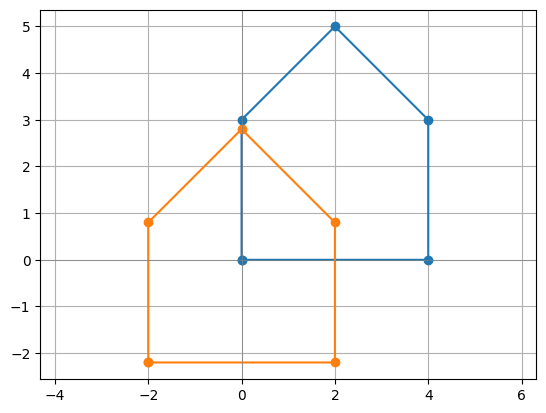

In [77]:
center = np.mean(house, axis=0)
centered = house - center
print(center, np.mean(centered, axis=0))
draw(house, centered)

## Sorting, searching, statistics

`np.argmax`, `np.argmin`, `np.argsort` return **positions**: use them to look up names.

**Live coding:** who got the best grade? Ranking from best to worst.

Statistics (`np.mean`, `np.median`, `np.std`, `np.var`) and math functions (`np.sqrt`, `np.exp`, ...) work as you expect: see the notes.

In [78]:
print(students[np.argmax(final_grades)])
for i in np.argsort(final_grades)[::-1]:
    print(students[i], final_grades[i])
print(np.mean(final_grades), np.std(final_grades))

Chloe
Emma 9.0
Chloe 9.0
Ana 8.0
Farid 5.0
Bruno 5.0
Diego 4.5
6.75 1.9525624189766635


### Exercise: The farthest corner

The norm of $(x, y)$ is $\sqrt{x^2 + y^2}$. Find the corner of the house farthest from the origin, without a loop.

In [79]:
distances = np.sqrt(np.sum(house ** 2, axis=1))
print(distances)
print(corners[np.argmax(distances)])

[0.         4.         5.         5.38516481 3.        ]
roof


## Matrices

- `*` is element-wise; `@` is matrix multiplication.
- Dot product: `u @ v`, the same as `np.sum(u * v)`.
- **The grades, again:** `marks @ weights / 10`, one dot product per student.

**Linear transformations.** A matrix $M$ transforms point $p$ into $Mp$. Our points are rows, so all at once: `house @ M.T`.

```python
H = np.array([[1, 1], [0, 1]])    # shear
```

- `np.linalg.det(H)`: how areas change (1: same area).
- `np.linalg.inv(H)`: undoes the transformation.

1 1
[8.  5.  9.  4.5 9.  5. ]


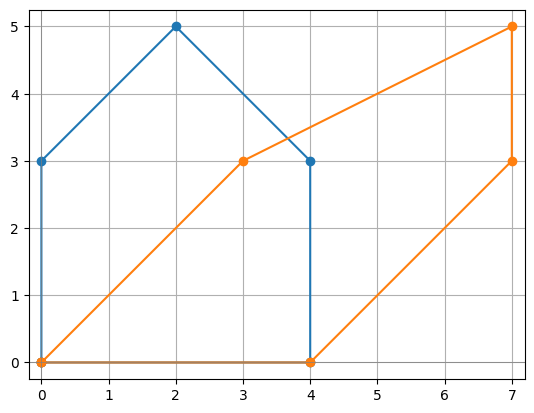

1.0
True


In [80]:
print(u @ v, np.sum(u * v))

print(marks @ weights / 10)

H = np.array([[1, 1], [0, 1]])
sheared = house @ H.T
draw(house, sheared)
print(np.linalg.det(H))
print(np.allclose(sheared @ np.linalg.inv(H).T, house))

### Rotation: trigonometry meets matrices

NumPy works in radians: `np.radians(90)`.

$$R(\theta)=\begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix}$$

Build $R(90^\circ)$ and rotate the house. Why `6.1e-17` instead of 0?

[[ 0. -1.]
 [ 1.  0.]]


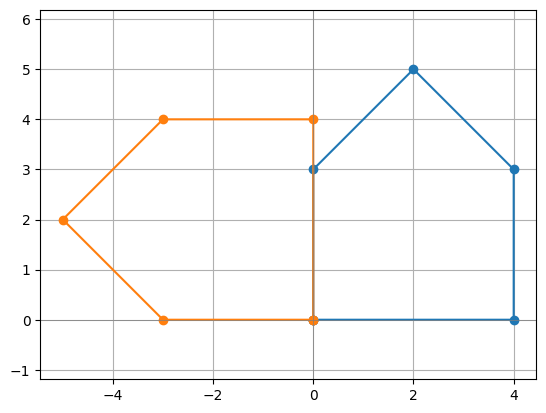

In [81]:
t = np.radians(90)
R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
print(np.round(R, 10))
draw(house, house @ R.T)

## Challenge

Deactivate AI assistant tools.

Rotate the house 90° and then stretch it horizontally by 2, with `S = np.array([[2, 0], [0, 1]])`.

1. Build $M = S R$ and draw the transformed house.
2. Is $SR$ the same as $RS$?
3. By how much did the area change?
4. Recover the original house.

More in the notes: flipping images with matrices, the magic square exercises.

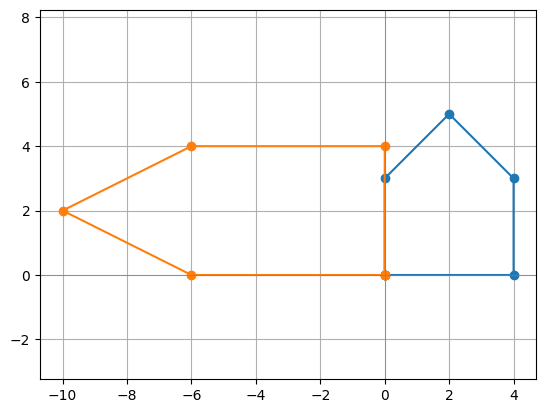

False
2.0
True


In [82]:
S = np.array([[2, 0], [0, 1]])
M = S @ R
new_house = house @ M.T
draw(house, new_house)
print(np.allclose(S @ R, R @ S))
print(np.linalg.det(M))
print(np.allclose(new_house @ np.linalg.inv(M).T, house))

## Summary

- Operators act element by element; broadcasting stretches compatible shapes.
- `axis` chooses the dimension that disappears.
- `*` element-wise, `@` matrix product. Many points transformed at once: `points @ M.T`.

**Question:** a stretch can be done with broadcasting (`house * [2, 1]`), but a rotation cannot. Why?

Next: who passed? (masking, later in the module). Homework: Array Arithmetic and Broadcasting exercises.